# 6. Concentration, profiles and the halo field

This notebook follows Secs. 3.4–3.7 of Paper I.
It shows which concentration relations a $200{\rm m}$ field admits, the Fourier-space NFW profile and its cosmological response, the beyond-linear halo bias, and the `HaloField` that holds every rung of the layer.
It ends on the figures of the concentration and the profile.

In [1]:
import jax
jax.config.update("jax_enable_x64", True)   # before the first ggah_mod import

from importlib.metadata import version

import jax.numpy as jnp
import matplotlib.pyplot as plt
import numpy as np

import _helpers as T
T.paper_style()
FAST = T.fast_mode()
for name in ("ggah_mod", "emu_pk", "jax", "numpy"):
    print(f"{name:9s} {version(name)}")
print("FAST =", FAST)

import ggah_mod.halos as H
from ggah_mod import DIFFERENTIABLE
from ggah_mod.cosmology import PLANCK18, make_pk
from ggah_mod.halos.field import make_field

pk = make_pk("emu_pk")
c = PLANCK18
M = np.logspace(10.0, 16.0, 80 if FAST else 160)     # h^-1 Msun
K = np.logspace(-4.0, 2.0, 512)                      # h Mpc^-1
mj, kj = jnp.asarray(M), jnp.asarray(K)
near = lambda arr, value: int(np.argmin(np.abs(np.asarray(arr) - value)))

#: The four model choices of Sec. 3: the defaults of the DIFFERENTIABLE backend.
CHOICE = dict(mdef="200m", hmf_model="tinker08", bias_model="tinker10", cm_model="bhattacharya13")


def field(cosmo, **kw):
    """The halo field of Eq. (36) at ``cosmo`` on this notebook's grids."""
    return make_field(cosmo, DIFFERENTIABLE, pk, z=0.0, m=M, k=K, **{**CHOICE, **kw})


def dln(read):
    """``{param: d ln read(field) / d theta}`` by forward autodiff of the whole field."""
    out = {}
    for p in T.DPARAMS:
        v0 = float(getattr(c, p))
        scale = v0 if p in T.DLOG else 1.0
        out[p] = np.asarray(jax.jacfwd(lambda v, p=p: jnp.log(read(field(c.replace(**{p: v})))))(v0)) * scale
    return out


#: The directions the left-hand panels move, either side of the fiducial.
VARIANTS = (("Omega_m", 0.28), ("Omega_m", 0.34), ("h", 0.65), ("h", 0.70),
            ("Omega_k", -0.05), ("Omega_k", 0.05))


def variant_lines(axis, of, x):
    for p, v in VARIANTS:
        ls = (0, (5, 1.6)) if v < float(getattr(c, p)) else (0, (1, 1.4))
        axis.plot(x, of(c.replace(**{p: v})), color=T.DSTYLE[p][0], ls=ls, lw=1.1,
                  label=T.TEX[p][:-1] + rf" = {v:g}$")


def gradient_panel(axis, x, g, xlabel, ylabel, title, lin=1e-2):
    axis.grid(False)
    axis.axhspan(-lin, lin, color="0.90", zorder=0)
    for p in T.DPARAMS:
        if not np.all(g[p] == 0.0):
            colour, ls = T.DSTYLE[p]
            axis.plot(x, g[p], color=colour, ls=ls, lw=1.3, label=T.TEX[p])
    axis.axhline(0.0, color="k", lw=0.8)
    axis.set_xscale("log")
    axis.set_yscale("symlog", linthresh=lin)
    axis.set(xlabel=xlabel, ylabel=ylabel, title=title)
    axis.set_xlim(float(np.min(x)), float(np.max(x)))


def mass_axis_on_sigma(axis, sigma, masses=(1e10, 1e12, 1e13, 1e14, 1e15, 1e16)):
    """Masses along the top of a panel drawn against sigma, at the fiducial."""
    import matplotlib.ticker as mticker
    top = axis.twiny()
    top.grid(False)
    top.set_xscale("log")
    top.set_xlim(axis.get_xlim())
    top.set_xticks([float(np.exp(np.interp(np.log(mm), np.log(M), np.log(sigma)))) for mm in masses])
    top.set_xticklabels([rf"$10^{{{int(np.log10(mm))}}}$" for mm in masses])
    top.xaxis.set_minor_formatter(mticker.NullFormatter())
    top.set_xlabel(r"$M\ [h^{-1}M_\odot]$ at the fiducial")
    axis.set_xticks([t for t in (0.3, 0.5, 1.0, 2.0, 3.0) if sigma.min() <= t <= sigma.max()])
    axis.xaxis.set_major_formatter(mticker.FormatStrFormatter("%g"))
    axis.xaxis.set_minor_formatter(mticker.NullFormatter())


def bottom_legend(fig, axis):
    handles, labels = axis.get_legend_handles_labels()
    fig.legend(handles, labels, fontsize=6.6, ncol=10, loc="lower center", bbox_to_anchor=(0.5, -0.015),
               frameon=False, handlelength=1.5, columnspacing=1.0, handletextpad=0.4)
    fig.tight_layout(rect=(0, 0.055, 1, 1))


fid = field(c)
sigma = np.asarray(fid.sigma)

An NVIDIA GPU may be present on this machine, but a CUDA-enabled jaxlib is not installed. Falling back to cpu.


ggah_mod  1.7.0
emu_pk    2.1.1
jax       0.10.2
numpy     2.4.6
FAST = True


## Concentration

Six relations are provided, in two families (Eq. 33): empirical power laws $c(M, z, \Delta)$ (`duffy08`, `dutton14`, `klypin16`), which cannot see a cosmology, and peak-height relations $c(\sigma, \cdot)$ (`bhattacharya13`, `diemer19`, `seppi21`), which see it through $\sigma(M)$.
`CM_CALIBRATION` records the simulation, the mass definitions and the redshift range of each.
We ask for each of the six at $200{\rm m}$; the ones calibrated at another mass definition are refused rather than converted.

In [2]:
cm = {}
for name in H.CONCENTRATION:
    try:
        cm[name] = np.asarray(field(c, cm_model=name).conc)
    except Exception as err:
        print(f"{name:15s} refused at 200m: {type(err).__name__}")
lo, hi = near(M, 1e12), near(M, 1e14)
for name, v in cm.items():
    print(f"{name:15s} c(1e12) = {v[lo]:6.3f}   c(1e14) = {v[hi]:6.3f}")
d12 = cm["duffy08"][lo] / cm["bhattacharya13"][lo] - 1
d14 = cm["duffy08"][hi] / cm["bhattacharya13"][hi] - 1
print(f"duffy08 / bhattacharya13 - 1: {d12:+.0%} at 1e12, {d14:+.0%} at 1e14   (paper: 11%, 3%)")

same = np.array_equal(np.asarray(field(c, cm_model="duffy08").conc),
                      np.asarray(field(c.replace(Omega_m=0.34), cm_model="duffy08").conc))
print("duffy08 identical at Omega_m = 0.3153 and 0.34:", same)

dutton14        refused at 200m: ValueError
klypin16        refused at 200m: ValueError
diemer19        refused at 200m: ValueError
seppi21         refused at 200m: ValueError
duffy08         c(1e12) = 10.776   c(1e14) =  7.351
bhattacharya13  c(1e12) =  9.665   c(1e14) =  7.568
duffy08 / bhattacharya13 - 1: +12% at 1e12, -3% at 1e14   (paper: 11%, 3%)
duffy08 identical at Omega_m = 0.3153 and 0.34: True


`bhattacharya13` is $c = K D^{\alpha}\nu^{\beta}$ with $\beta = -0.29$ at $200{\rm m}$ in the form used here.
At $z = 0$ the growth factor is one and carries no derivative, so every cosmological direction of the concentration is $0.29$ times the corresponding direction of $\sigma(M)$.

In [3]:
g_c = dln(lambda f: f.conc)
g_s = dln(lambda f: f.sigma)
worst = max(float(np.max(np.abs(g_c[p] - 0.29 * g_s[p]))) for p in T.DPARAMS)
print(f"d ln c / d theta = 0.29 d ln sigma / d theta to {worst:.1e}")
assert worst < 1e-8

d ln c / d theta = 0.29 d ln sigma / d theta to 3.9e-16


Fig. 7 of the paper.

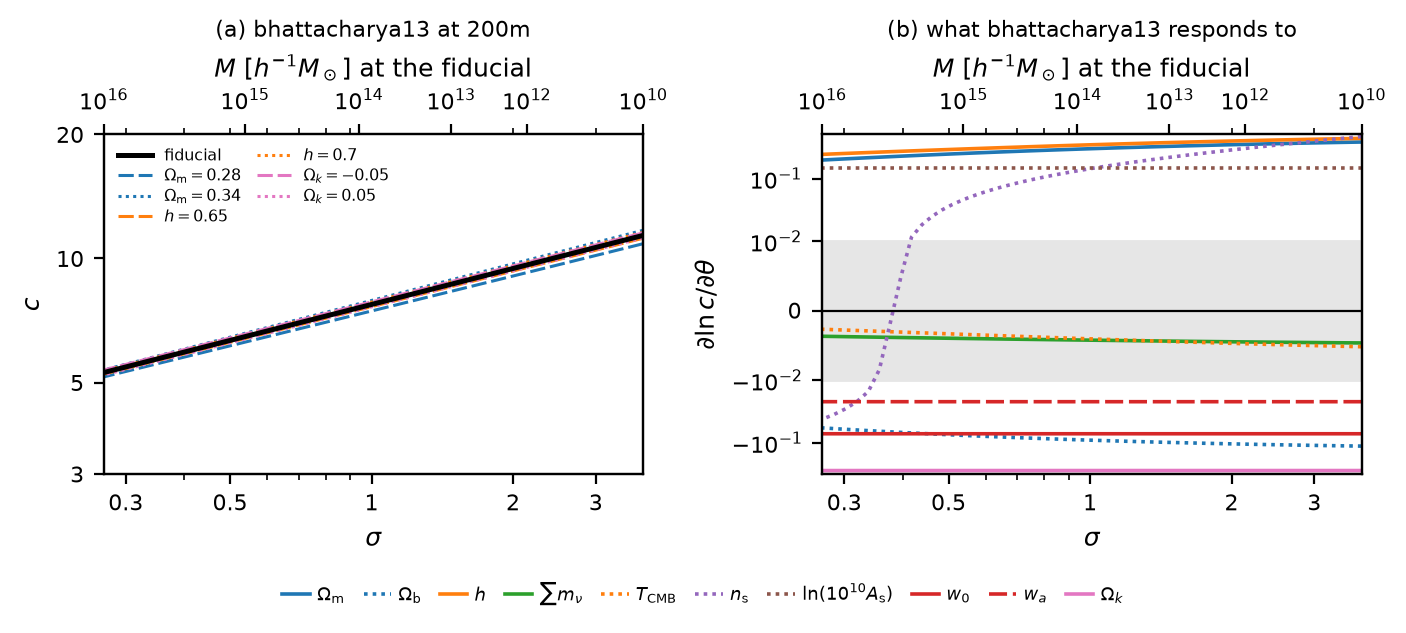

In [4]:
fig, ax = plt.subplots(1, 2, figsize=(7.1, 3.1))
ax[0].grid(False)
ax[0].loglog(sigma, cm["bhattacharya13"], "k", lw=1.8, zorder=3, label="fiducial")
variant_lines(ax[0], lambda cc: np.asarray(field(cc).conc), sigma)
ax[0].set(xlabel=r"$\sigma$", ylabel=r"$c$", title=r"(a) bhattacharya13 at $200\mathrm{m}$",
          xlim=(sigma.min(), sigma.max()))
ax[0].set_yticks([3, 5, 10, 20])
ax[0].set_yticks([], minor=True)
ax[0].set_yticklabels(["3", "5", "10", "20"])
ax[0].legend(fontsize=5.6, ncol=2, loc="upper left", frameon=False, handlelength=2.2, labelspacing=0.3, columnspacing=1.0)
mass_axis_on_sigma(ax[0], sigma)
gradient_panel(ax[1], sigma, g_c, r"$\sigma$", r"$\partial\ln c/\partial\theta$", "(b) what bhattacharya13 responds to")
mass_axis_on_sigma(ax[1], sigma)
bottom_legend(fig, ax[1])
T.save_figure(fig, "fig_concentration")

## Profiles

The halo model needs the normalised Fourier transform of the radial profile (Eq. 34),

$$u(k|M) = \frac{4\pi}{M}\int_0^{r_\Delta}\rho(r)\frac{\sin kr}{kr}r^2\,{\rm d}r,\qquad u(k\to0|M) = 1.$$

For NFW truncated at $r_\Delta = c\,r_{\rm s}$ the integral is analytic in sine and cosine integrals (Eq. 37), with $\kappa = kr_{\rm s}$ and $g(c) = \ln(1+c) - c/(1+c)$:

$$u(k) = \frac{1}{g(c)}\Big\{\sin\kappa\,[{\rm Si}((1+c)\kappa) - {\rm Si}(\kappa)] + \cos\kappa\,[{\rm Ci}((1+c)\kappa) - {\rm Ci}(\kappa)] - \frac{\sin c\kappa}{(1+c)\kappa}\Big\}.$$

Einasto, generalised NFW and others are provided too; `profile_uk_gl` is the Gauss–Legendre transform any new profile gets its $u(k)$ from.
We check the analytic NFW transform against it.

In [5]:
i13 = near(M, 1e13)
rs, cc13 = fid.r_s[i13], fid.conc[i13]
kk = np.logspace(-1, 2, 50)
u_nfw = np.ravel(H.nfw_uk(jnp.asarray(kk), rs, cc13))
nfw_shape = lambda r: 1.0 / ((r / rs) * (1.0 + r / rs) ** 2)      # rho_s cancels in u(k)
u_gl = np.ravel(H.profile_uk_gl(jnp.asarray(kk), jnp.array([cc13 * rs]), nfw_shape, n_gl=400))
print(f"M = 1e13: max |Gauss-Legendre / analytic - 1| on 0.1 < k < 100 = {np.max(np.abs(u_gl / u_nfw - 1)):.1e}")

M = 1e13: max |Gauss-Legendre / analytic - 1| on 0.1 < k < 100 = 2.3e-12


In [6]:
KP = np.logspace(-3.0, 3.0, 160 if FAST else 320)
kp = jnp.asarray(KP)
MASSES = (1e12, 1e13, 1e14)
idx = [near(M, m) for m in MASSES]


def read_uk(f):
    return jnp.stack([jnp.ravel(H.nfw_uk(kp, f.r_s[i], f.conc[i])) for i in idx])


u = np.asarray(read_uk(fid))
for j, i in enumerate(idx):
    print(f"M = {MASSES[j]:.0e}: c = {float(fid.conc[i]):.2f}  r_s = {float(fid.r_s[i]):.4f} Mpc/h  "
          f"1/r_s = {1 / float(fid.r_s[i]):.1f} h/Mpc")
g_u = dln(read_uk)
g_mid = {p: v[1] for p, v in g_u.items()}

M = 1e+12: c = 9.66  r_s = 0.0242 Mpc/h  1/r_s = 41.2 h/Mpc
M = 1e+13: c = 8.70  r_s = 0.0575 Mpc/h  1/r_s = 17.4 h/Mpc
M = 1e+14: c = 7.57  r_s = 0.1494 Mpc/h  1/r_s = 6.7 h/Mpc


Fig. 8 of the paper.
Panel (a) is $u(k|M)$ at three masses, each turning over at its own $1/r_{\rm s}$ (dotted); the top axis is $1/k$.
Panel (b) is $\partial\ln u/\partial\theta$ at $10^{13}\,h^{-1}{\rm M}_\odot$.

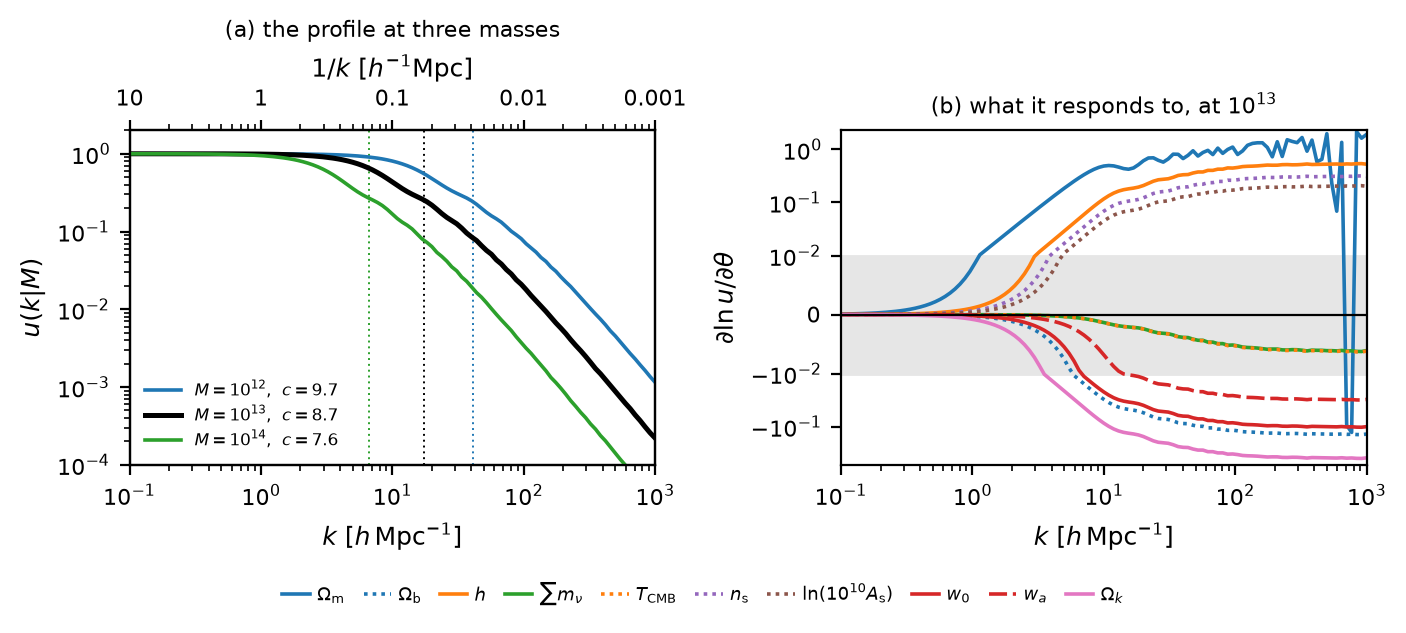

In [7]:
fig, ax = plt.subplots(1, 2, figsize=(7.1, 3.1))
ax[0].grid(False)
for j, i in enumerate(idx):
    col = "k" if j == 1 else f"C{j}"
    ax[0].loglog(KP, u[j], color=col, lw=1.8 if j == 1 else 1.3, zorder=3,
                 label=rf"$M = 10^{{{int(np.log10(MASSES[j]))}}}$,  $c = {float(fid.conc[i]):.1f}$")
    ax[0].axvline(1.0 / float(fid.r_s[i]), color=col, lw=0.7, ls=(0, (1, 2)))
ax[0].set(xlabel=r"$k\ [h\,\mathrm{Mpc}^{-1}]$", ylabel=r"$u(k|M)$", title="(a) the profile at three masses",
          xlim=(0.1, KP[-1]), ylim=(1e-4, 2.0))
ax[0].legend(fontsize=6.0, loc="lower left", frameon=False, handlelength=2.2, labelspacing=0.3)
top = ax[0].twiny()
top.grid(False)
top.set_xscale("log")
top.set_xlim(ax[0].get_xlim())
radii = [r for r in (10.0, 1.0, 0.1, 0.01, 0.001) if 0.1 <= 1 / r <= KP[-1]]
top.set_xticks([1 / r for r in radii])
top.set_xticklabels([f"{r:g}" for r in radii])
top.set_xlabel(r"$1/k\ [h^{-1}\mathrm{Mpc}]$")
gradient_panel(ax[1], KP, g_mid, r"$k\ [h\,\mathrm{Mpc}^{-1}]$", r"$\partial\ln u/\partial\theta$",
               r"(b) what it responds to, at $10^{13}$")
ax[1].set_xlim(0.1, KP[-1])
bottom_legend(fig, ax[1])
T.save_figure(fig, "fig_profile")

## Beyond-linear halo bias

Haloes are not linearly biased tracers of the linear field at intermediate scales.
Mead & Verde (2021) tabulate the residual from the MultiDark simulation (Eq. 38),

$$P_{hh}(\nu_1,\nu_2,k) = b(\nu_1)b(\nu_2)P_{\rm lin}(k)\big[1 + \beta^{\rm NL}(k,\nu_1,\nu_2)\big].$$

All 35 public snapshots are shipped, and the one matching the user's cosmology and redshift is selected by the Angulo & White (2010) rescaling.
It is computed in this layer and consumed by the two-halo term of layer 4.

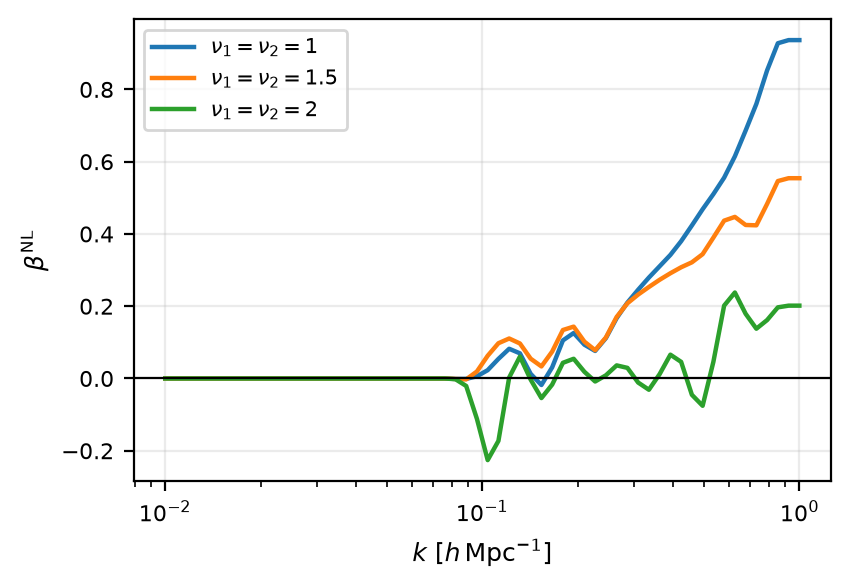

In [8]:
kb = np.logspace(-2, 0, 60)
nus = np.array([1.0, 1.5, 2.0])
# the MultiDark snapshot is chosen by matching sigma(R) of this spectrum (Angulo & White 2010)
table = H.beyond_linear_bias.table_at(kb, k=kj, pk_cb=pk.pk_cb(kj, 0.0, c))
beta = np.asarray(H.beta_nl(kb, nus, nus, table=table))   # shape (Nk, N1, N2)
fig, ax = plt.subplots(figsize=(4.5, 3.0))
for j, n in enumerate(nus):
    ax.semilogx(kb, beta[:, j, j], label=rf"$\nu_1 = \nu_2 = {n:g}$")
ax.axhline(0.0, color="k", lw=0.8)
ax.set(xlabel=r"$k\ [h\,\mathrm{Mpc}^{-1}]$", ylabel=r"$\beta^{\rm NL}$")
ax.legend();

## The halo field

`HaloField` holds every rung of the layer on shared grids, as differentiable leaves of one pytree (Eq. 40): $M$, $k$, $z$, $\sigma$, ${\rm d}\ln\sigma/{\rm d}\ln M$, $\nu$, ${\rm d}n/{\rm d}M$, $b$, $c$, $r_\Delta$, $r_{\rm s}$, $P_{\rm cb}$, $P_{\rm lin}$ and the cosmology.
The four model choices are static.
`make_field` takes its grids and choices from the backend, so a flavour is selected once.
Anything computed from a field is differentiable with respect to the cosmology, as every derivative in notebooks 04–06 was.

In [9]:
default = make_field(c, DIFFERENTIABLE, pk)
print(type(default).__name__, "on", default.m.shape[0], "masses and", default.k.shape[0], "wavenumbers")
print("choices:", default.mdef, default.hmf_model, default.bias_model, default.cm_model)


def mean_bias_above(om, m_min=1e13):
    f = make_field(c.replace(Omega_m=om), DIFFERENTIABLE, pk)
    w = jnp.where(f.m > m_min, f.dndm * f.m, 0.0)
    return jnp.sum(w * f.bias) / jnp.sum(w)


print(f"mass-weighted bias above 1e13: {float(mean_bias_above(c.Omega_m)):.4f}; "
      f"d/dOmega_m = {float(jax.grad(mean_bias_above)(c.Omega_m)):+.4f}")

HaloField on 256 masses and 512 wavenumbers
choices: 200m tinker08 tinker10 bhattacharya13


mass-weighted bias above 1e13: 1.3974; d/dOmega_m = -5.4520


## Exercises

1. Replace NFW by an Einasto profile with the same $r_{\rm s}$ and $c$ and plot the ratio of the two $u(k)$. At which $k$ does the choice of profile matter at $10^{14}\,h^{-1}{\rm M}_\odot$?
2. Build the field at $z = 1$ and compare the concentrations of `bhattacharya13` with those at $z = 0$. Through which term does redshift enter?
3. Compute $\partial\ln b/\partial\theta$ for `tinker10` at fixed mass, and check that it factors through $\sigma(M)$ as the multiplicity function did in notebook 05.

Next: notebook 07, cosmological constraints from distance measurements.